# Parte Comum — Análise Exploratória (Obesity)

Dataset: *Estimation of obesity levels based on eating habits and physical condition* (UCI 544).

Organizado nos quatro pilares:
1. **Estrutural** — dimensões, tipos, qualidade dos dados
2. **Distribucional** — distribuição de cada variável
3. **Relacional** — relações entre as variáveis, incluindo a classe
4. **Outliers** — identificação e tratamento

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve().parents[1] if Path.cwd().name == "parte_comum" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.parte_comum import kmeans as km

OUT = RAIZ / "out" / "parte_comum" / "eda"
OUT.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 50)

def salvar(fig, nome):
    fig.savefig(OUT / nome, dpi=150, bbox_inches="tight")

df = km.carregar_dados()
ALVO = km.ALVO
ORDEM = km.ORDEM_CLASSES
df[ALVO] = pd.Categorical(df[ALVO], categories=ORDEM, ordered=True)
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


## 1. Estrutural

### Dicionário das variáveis (segundo a documentação da UCI)

| Coluna | Significado |
|---|---|
| Gender | Gênero |
| Age | Idade (anos) |
| Height | Altura (m) |
| Weight | Peso (kg) |
| family_history_with_overweight | Histórico familiar de sobrepeso |
| FAVC | Consome alimentos muito calóricos com frequência |
| FCVC | Frequência de consumo de vegetais |
| NCP | Número de refeições principais por dia |
| CAEC | Come entre as refeições |
| SMOKE | Fuma |
| CH2O | Consumo diário de água |
| SCC | Monitora as calorias consumidas |
| FAF | Frequência de atividade física |
| TUE | Tempo de uso de dispositivos eletrônicos |
| CALC | Consumo de álcool |
| MTRANS | Meio de transporte usual |
| NObeyesdad | **Classe** — nível de obesidade (7 categorias) |

In [2]:
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")

numericas = df.select_dtypes("number").columns.tolist()
categoricas = [c for c in df.columns if c not in numericas]

estrutura = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "valores_unicos": df.nunique(),
    "faltantes": df.isna().sum(),
    "exemplo": df.iloc[0],
})
estrutura["grupo"] = np.where(estrutura.index.isin(numericas), "numérica", "categórica")
estrutura

Linhas: 2111 | Colunas: 17


,dtype,valores_unicos,faltantes,exemplo,grupo
Gender,str,2,0,Female,categórica
Age,float64,1402,0,21.0,numérica
Height,float64,1574,0,1.62,numérica
Weight,float64,1525,0,64.0,numérica
family_history_with_overweight,str,2,0,yes,categórica
FAVC,str,2,0,no,categórica
FCVC,float64,810,0,2.0,numérica
NCP,float64,635,0,3.0,numérica
CAEC,str,4,0,Sometimes,categórica
SMOKE,str,2,0,no,categórica


In [3]:
escalas = ["FCVC", "NCP", "CH2O", "FAF", "TUE"]
pd.DataFrame({
    "min": df[escalas].min(),
    "max": df[escalas].max(),
    "valores_unicos": df[escalas].nunique(),
    "% não inteiros": (df[escalas] % 1 != 0).mean() * 100,
})

,min,max,valores_unicos,% não inteiros
FCVC,1.0,3.0,810,39.128
NCP,1.0,4.0,635,30.317
CH2O,1.0,3.0,1268,61.108
FAF,0.0,3.0,1190,57.224
TUE,0.0,2.0,1129,54.619


In [4]:
for c in categoricas:
    print(f"{c}: {sorted(df[c].astype(str).unique())}")

Gender: ['Female', 'Male']
family_history_with_overweight: ['no', 'yes']
FAVC: ['no', 'yes']
CAEC: ['Always', 'Frequently', 'Sometimes', 'no']
SMOKE: ['no', 'yes']
SCC: ['no', 'yes']
CALC: ['Always', 'Frequently', 'Sometimes', 'no']
MTRANS: ['Automobile', 'Bike', 'Motorbike', 'Public_Transportation', 'Walking']
NObeyesdad: ['Insufficient_Weight', 'Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_II']


In [5]:
print("Total de valores faltantes:", int(df.isna().sum().sum()))
dup = df.duplicated()
print(f"Linhas duplicadas: {dup.sum()} ({dup.mean():.1%})")
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10)

Total de valores faltantes: 0
Linhas duplicadas: 24 (1.1%)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
295,Female,16.0,1.66,58.0,no,no,2.0,1.0,Sometimes,no,1.0,no,0.0,1.0,no,Walking,Normal_Weight
309,Female,16.0,1.66,58.0,no,no,2.0,1.0,Sometimes,no,1.0,no,0.0,1.0,no,Walking,Normal_Weight
282,Female,18.0,1.62,55.0,yes,yes,2.0,3.0,Frequently,no,1.0,no,1.0,1.0,no,Public_Transportation,Normal_Weight
460,Female,18.0,1.62,55.0,yes,yes,2.0,3.0,Frequently,no,1.0,no,1.0,1.0,no,Public_Transportation,Normal_Weight
97,Female,21.0,1.52,42.0,no,no,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
98,Female,21.0,1.52,42.0,no,no,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
523,Female,21.0,1.52,42.0,no,yes,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
527,Female,21.0,1.52,42.0,no,yes,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
659,Female,21.0,1.52,42.0,no,yes,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
663,Female,21.0,1.52,42.0,no,yes,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight


> ✍️ **Análise do grupo:**

**Qualidade dos dados.** O dataset parece relativamente limpo, pois possui 2.111 linhas, 17 colunas e nenhum valor faltante. Porém, existem 24 registros duplicados e valores decimais em variáveis que parecem representar respostas discretas de questionário. Por isso, ele está organizado, mas ainda exige algumas decisões de tratamento.

**Decimais nas respostas.** Isso acontece porque 77% dos dados foram gerados artificialmente com o SMOTE, segundo a [UCI](https://archive.ics.uci.edu/dataset/544). Esse método cria registros pela interpolação entre pessoas parecidas. Por exemplo, entre alguém que respondeu duas refeições e alguém que respondeu três, pode ser criado o valor 2,5. O decimal não representa necessariamente uma resposta dada por uma pessoa real.

## 2. Distribucional

In [6]:
desc = df[numericas].describe().T
desc["assimetria"] = df[numericas].skew()
desc["curtose"] = df[numericas].kurt()
desc

,count,mean,std,min,25%,50%,75%,max,assimetria,curtose
Age,2111.0,24.313,6.346,14.00,19.947,22.778,26.000,61.00,1.529,2.826
Height,2111.0,1.702,0.093,1.45,1.630,1.700,1.768,1.98,-0.013,-0.563
Weight,2111.0,86.586,26.191,39.00,65.473,83.000,107.431,173.00,0.255,-0.700
FCVC,2111.0,2.419,0.534,1.00,2.000,2.386,3.000,3.00,-0.433,-0.638
NCP,2111.0,2.686,0.778,1.00,2.659,3.000,3.000,4.00,-1.107,0.386
CH2O,2111.0,2.008,0.613,1.00,1.585,2.000,2.477,3.00,-0.105,-0.879
FAF,2111.0,1.010,0.851,0.00,0.125,1.000,1.667,3.00,0.498,-0.621
TUE,2111.0,0.658,0.609,0.00,0.000,0.625,1.000,2.00,0.619,-0.549


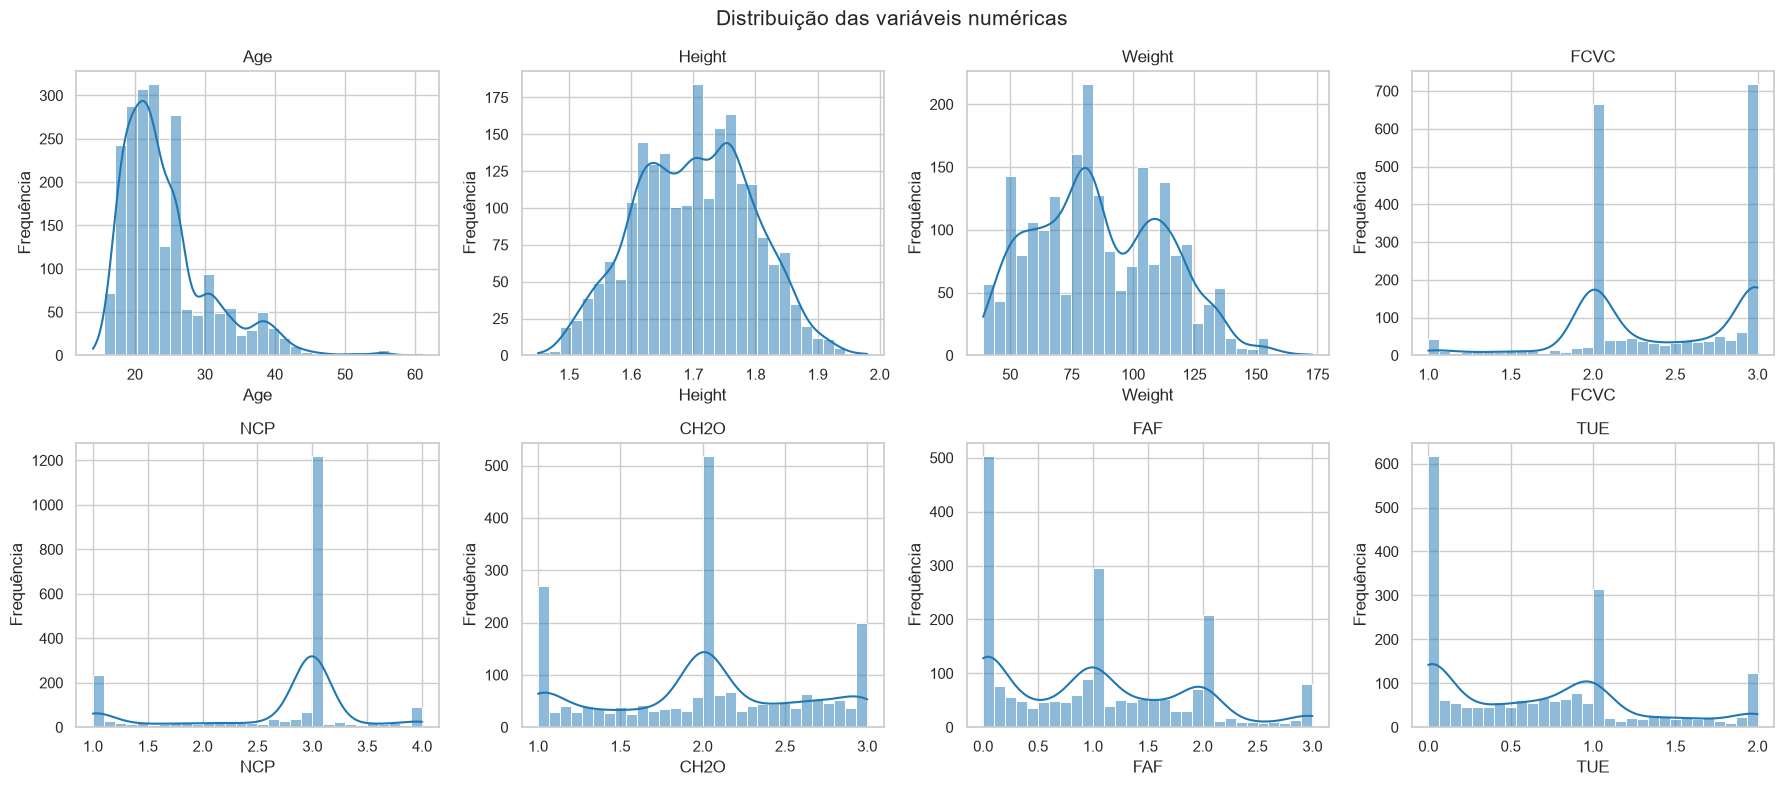

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, numericas):
    sns.histplot(df[col], kde=True, ax=ax, color="tab:blue", bins=30)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Frequência")
fig.suptitle("Distribuição das variáveis numéricas", fontsize=15)
fig.tight_layout()
salvar(fig, "dist_numericas.png")
plt.show()

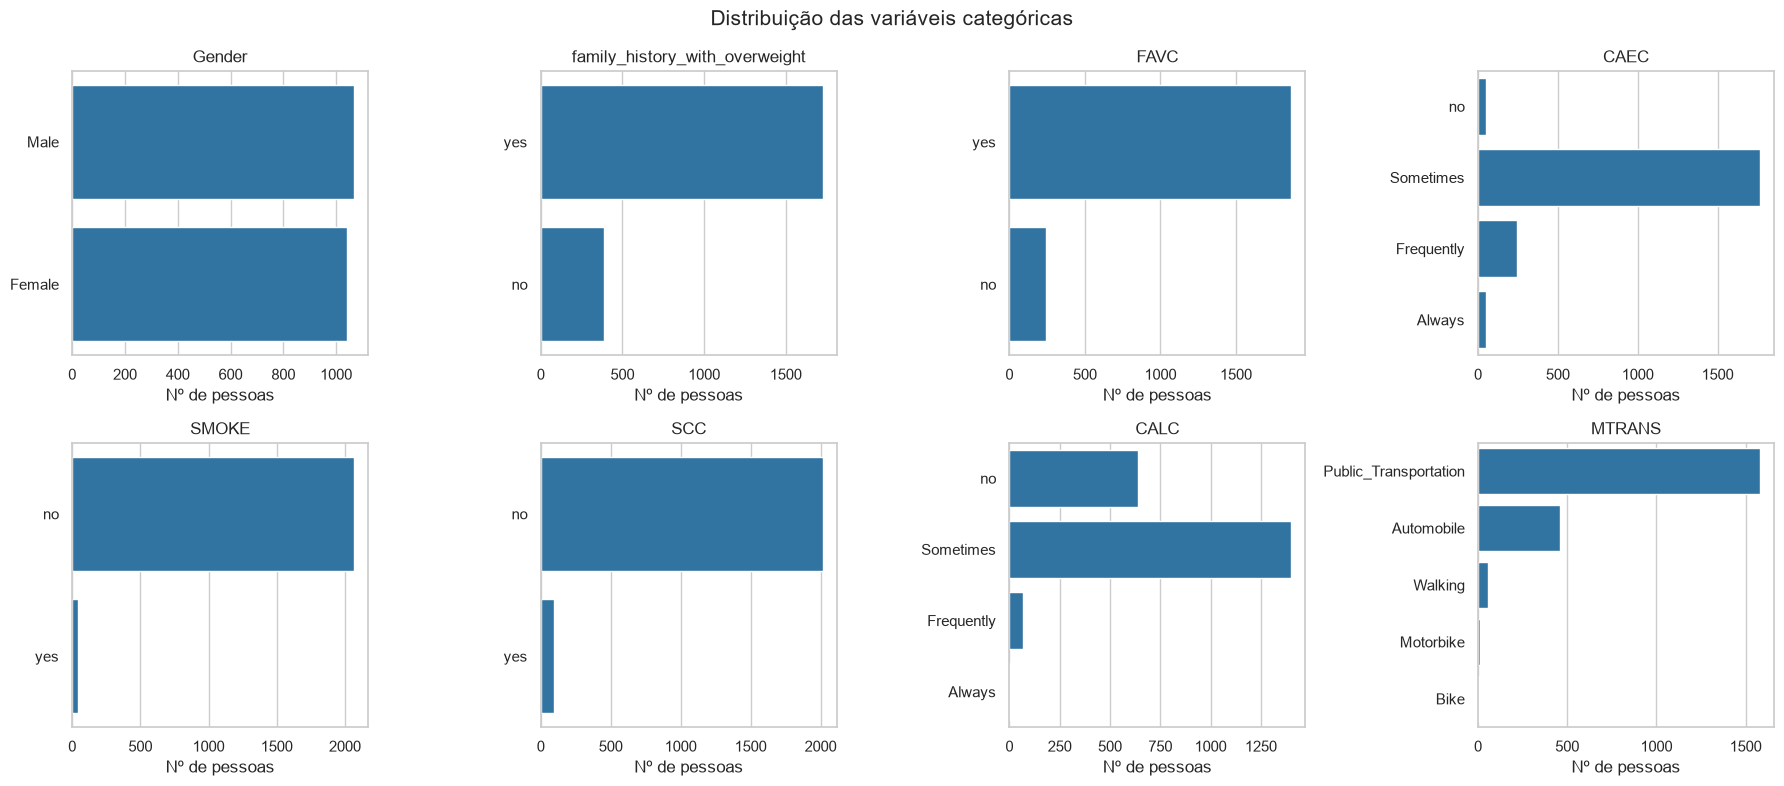

In [8]:
cats_sem_alvo = [c for c in categoricas if c != ALVO]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, cats_sem_alvo):
    ordem = ["no", "Sometimes", "Frequently", "Always"] if col in ("CAEC", "CALC") else df[col].value_counts().index
    sns.countplot(data=df, y=col, order=ordem, ax=ax, color="tab:blue")
    ax.set_title(col)
    ax.set_xlabel("Nº de pessoas")
    ax.set_ylabel("")
fig.suptitle("Distribuição das variáveis categóricas", fontsize=15)
fig.tight_layout()
salvar(fig, "dist_categoricas.png")
plt.show()

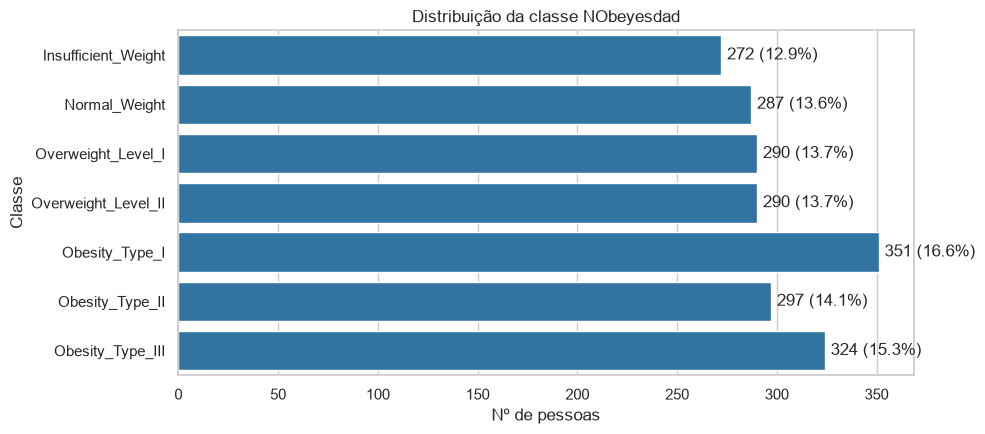

In [9]:
contagem = df[ALVO].value_counts().reindex(ORDEM)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=contagem.values, y=contagem.index, ax=ax, color="tab:blue")
for i, v in enumerate(contagem.values):
    ax.text(v + 3, i, f"{v} ({v / len(df):.1%})", va="center")
ax.set_title("Distribuição da classe NObeyesdad")
ax.set_xlabel("Nº de pessoas")
ax.set_ylabel("Classe")
fig.tight_layout()
salvar(fig, "dist_classe.png")
plt.show()

> ✍️ **Análise do grupo:**

**Idade.** A amostra é formada principalmente por pessoas jovens. A mediana é 22,8 anos e a média é 24,3. A assimetria positiva de 1,53 indica que existem poucas pessoas mais velhas, formando uma cauda que chega aos 61 anos.

**Equilíbrio das classes.** As classes estão equilibradas: possuem entre 272 e 351 pessoas, então nenhuma delas domina muito as outras. Isso ajuda tanto nas comparações quanto na construção de modelos, pois todas as classes possuem uma quantidade razoável de exemplos.

**Categorias concentradas.** Uma variável com 97,9% em uma categoria consegue explicar pouco, porque quase todas as pessoas apresentam a mesma resposta. No caso do tabagismo, como 97,9% não fumam, essa variável tem pouca capacidade de diferenciar os níveis de obesidade. Também existem poucos fumantes, então conclusões sobre esse grupo podem ser instáveis.

## 3. Relacional

### 3.1 Numéricas × numéricas

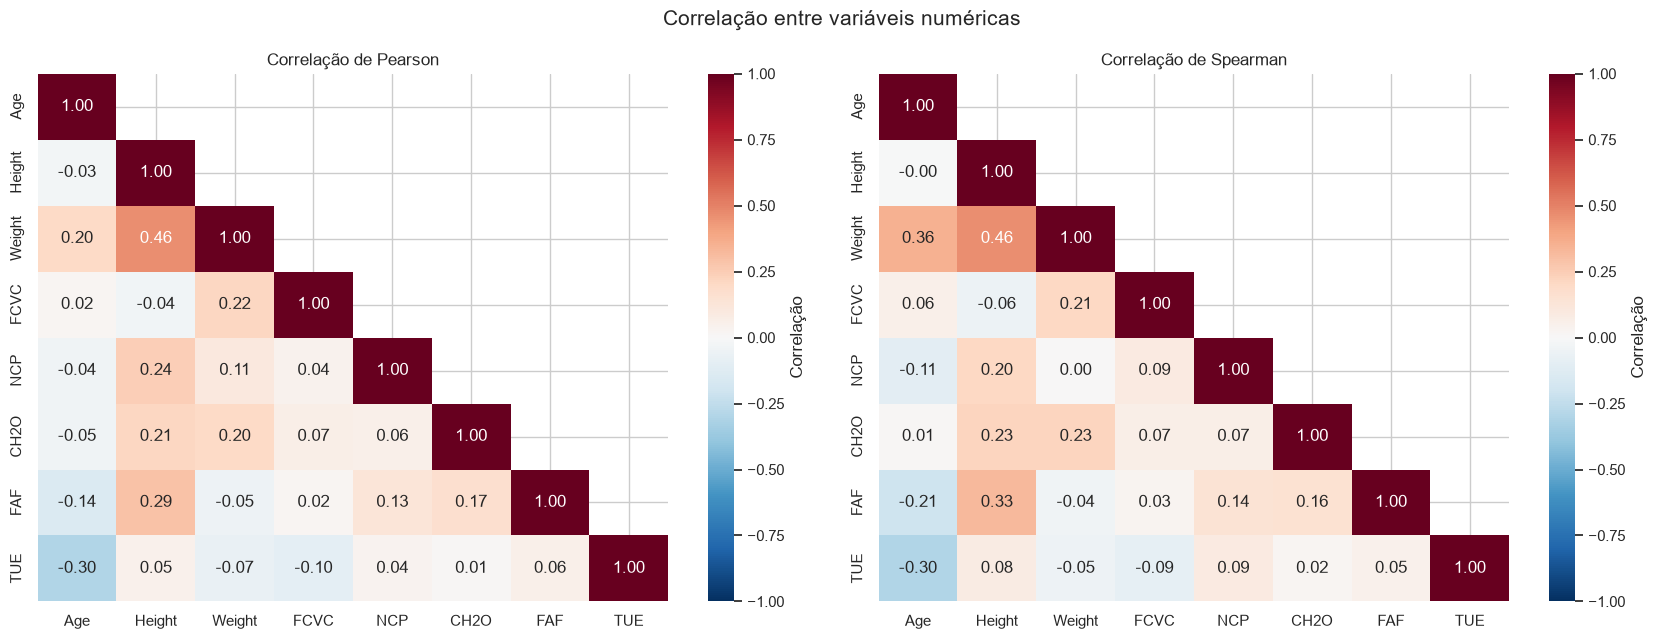

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, metodo in zip(axes, ["pearson", "spearman"]):
    corr = df[numericas].corr(method=metodo)
    mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
                cbar_kws={"label": "Correlação"}, ax=ax)
    ax.set_title(f"Correlação de {metodo.capitalize()}")
fig.suptitle("Correlação entre variáveis numéricas", fontsize=15)
fig.tight_layout()
salvar(fig, "corr_numericas.png")
plt.show()

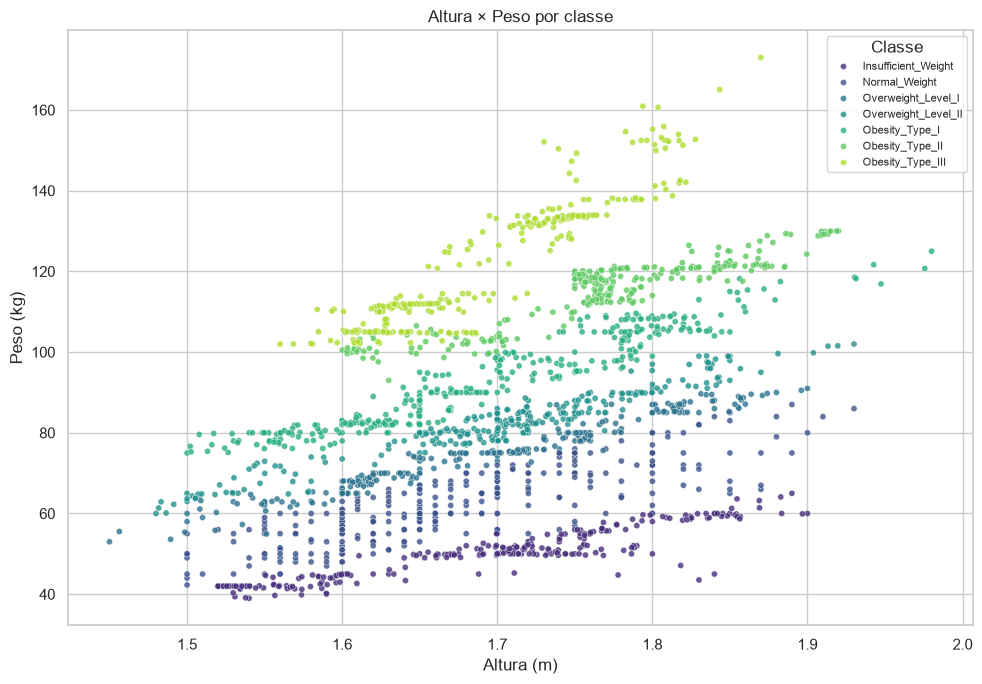

In [11]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=df, x="Height", y="Weight", hue=ALVO, palette="viridis", s=20, alpha=0.8, ax=ax)
ax.set_title("Altura × Peso por classe")
ax.set_xlabel("Altura (m)")
ax.set_ylabel("Peso (kg)")
ax.legend(title="Classe", fontsize=8)
fig.tight_layout()
salvar(fig, "altura_peso_classe.png")
plt.show()

### 3.2 Numéricas × classe

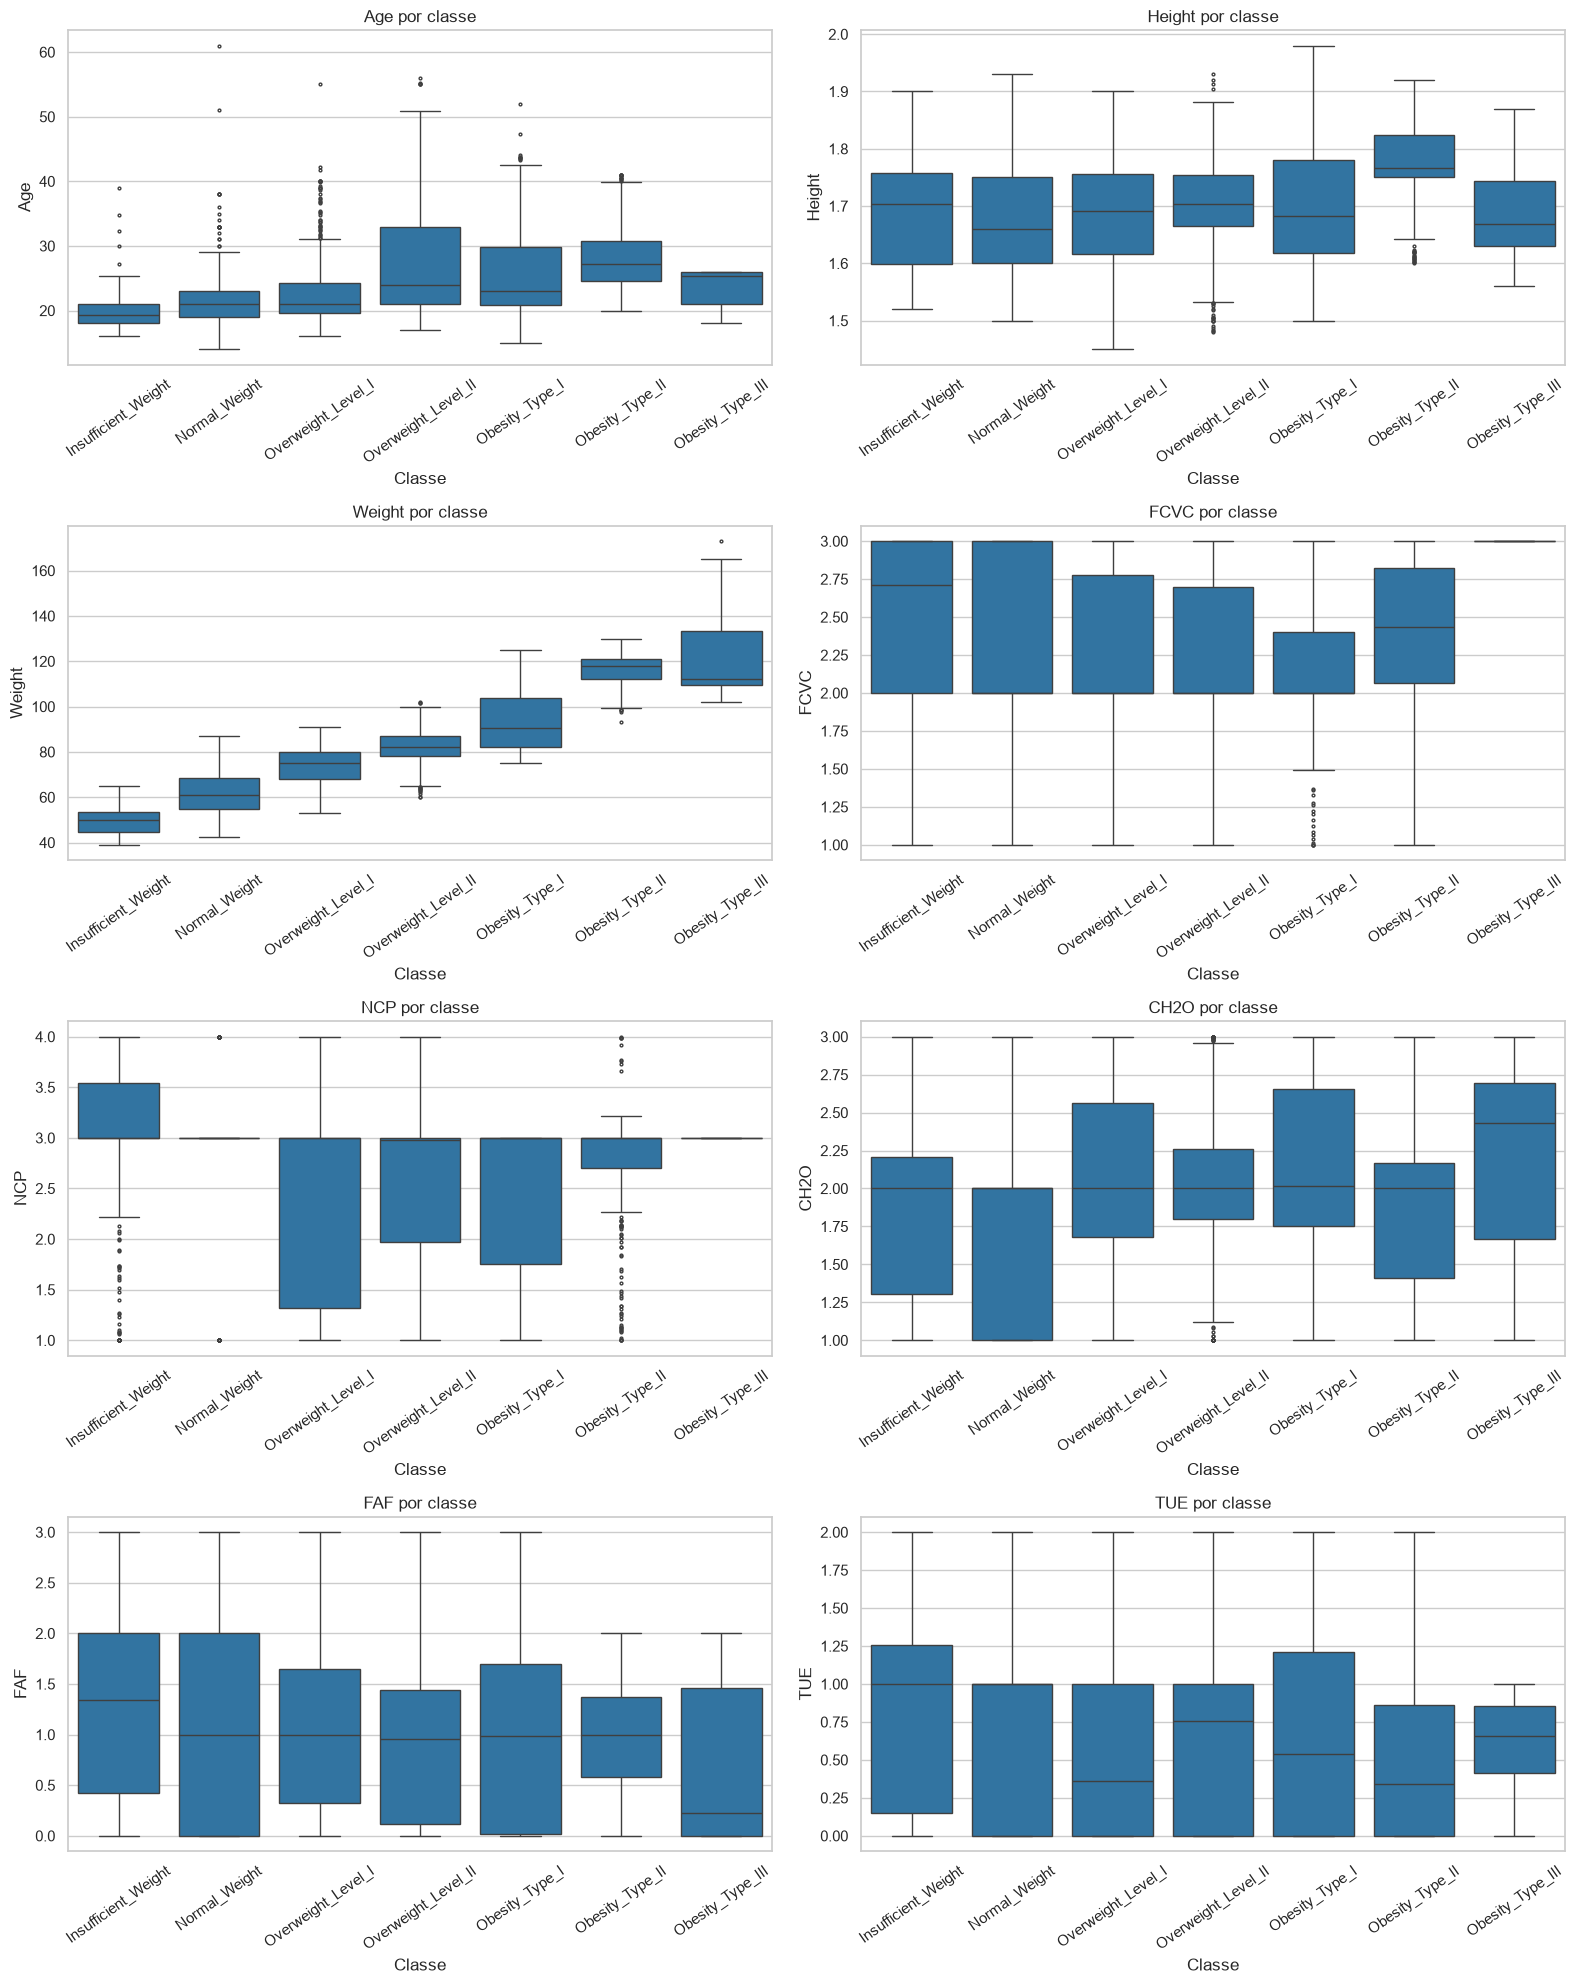

In [12]:
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
for ax, col in zip(axes.flat, numericas):
    sns.boxplot(data=df, x=ALVO, y=col, ax=ax, color="tab:blue", fliersize=2)
    ax.set_title(f"{col} por classe")
    ax.set_xlabel("Classe")
    ax.set_ylabel(col)
    ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
salvar(fig, "box_numericas_classe.png")
plt.show()

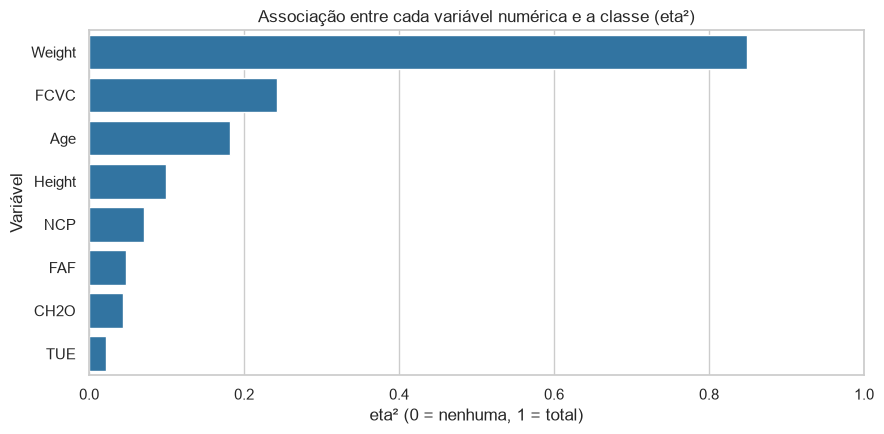

,eta²
Weight,0.849
FCVC,0.243
Age,0.182
Height,0.099
NCP,0.071
FAF,0.047
CH2O,0.044
TUE,0.022


In [13]:
def eta2(num, cat):
    media_geral = num.mean()
    grupos = num.groupby(cat, observed=True)
    ss_entre = (grupos.count() * (grupos.mean() - media_geral) ** 2).sum()
    ss_total = ((num - media_geral) ** 2).sum()
    return ss_entre / ss_total

eta = pd.Series({c: eta2(df[c], df[ALVO]) for c in numericas}, name="eta²").sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=eta.values, y=eta.index, ax=ax, color="tab:blue")
ax.set_title("Associação entre cada variável numérica e a classe (eta²)")
ax.set_xlabel("eta² (0 = nenhuma, 1 = total)")
ax.set_ylabel("Variável")
ax.set_xlim(0, 1)
fig.tight_layout()
salvar(fig, "eta2_classe.png")
plt.show()
eta.to_frame()

### 3.3 Categóricas × classe e categóricas × categóricas

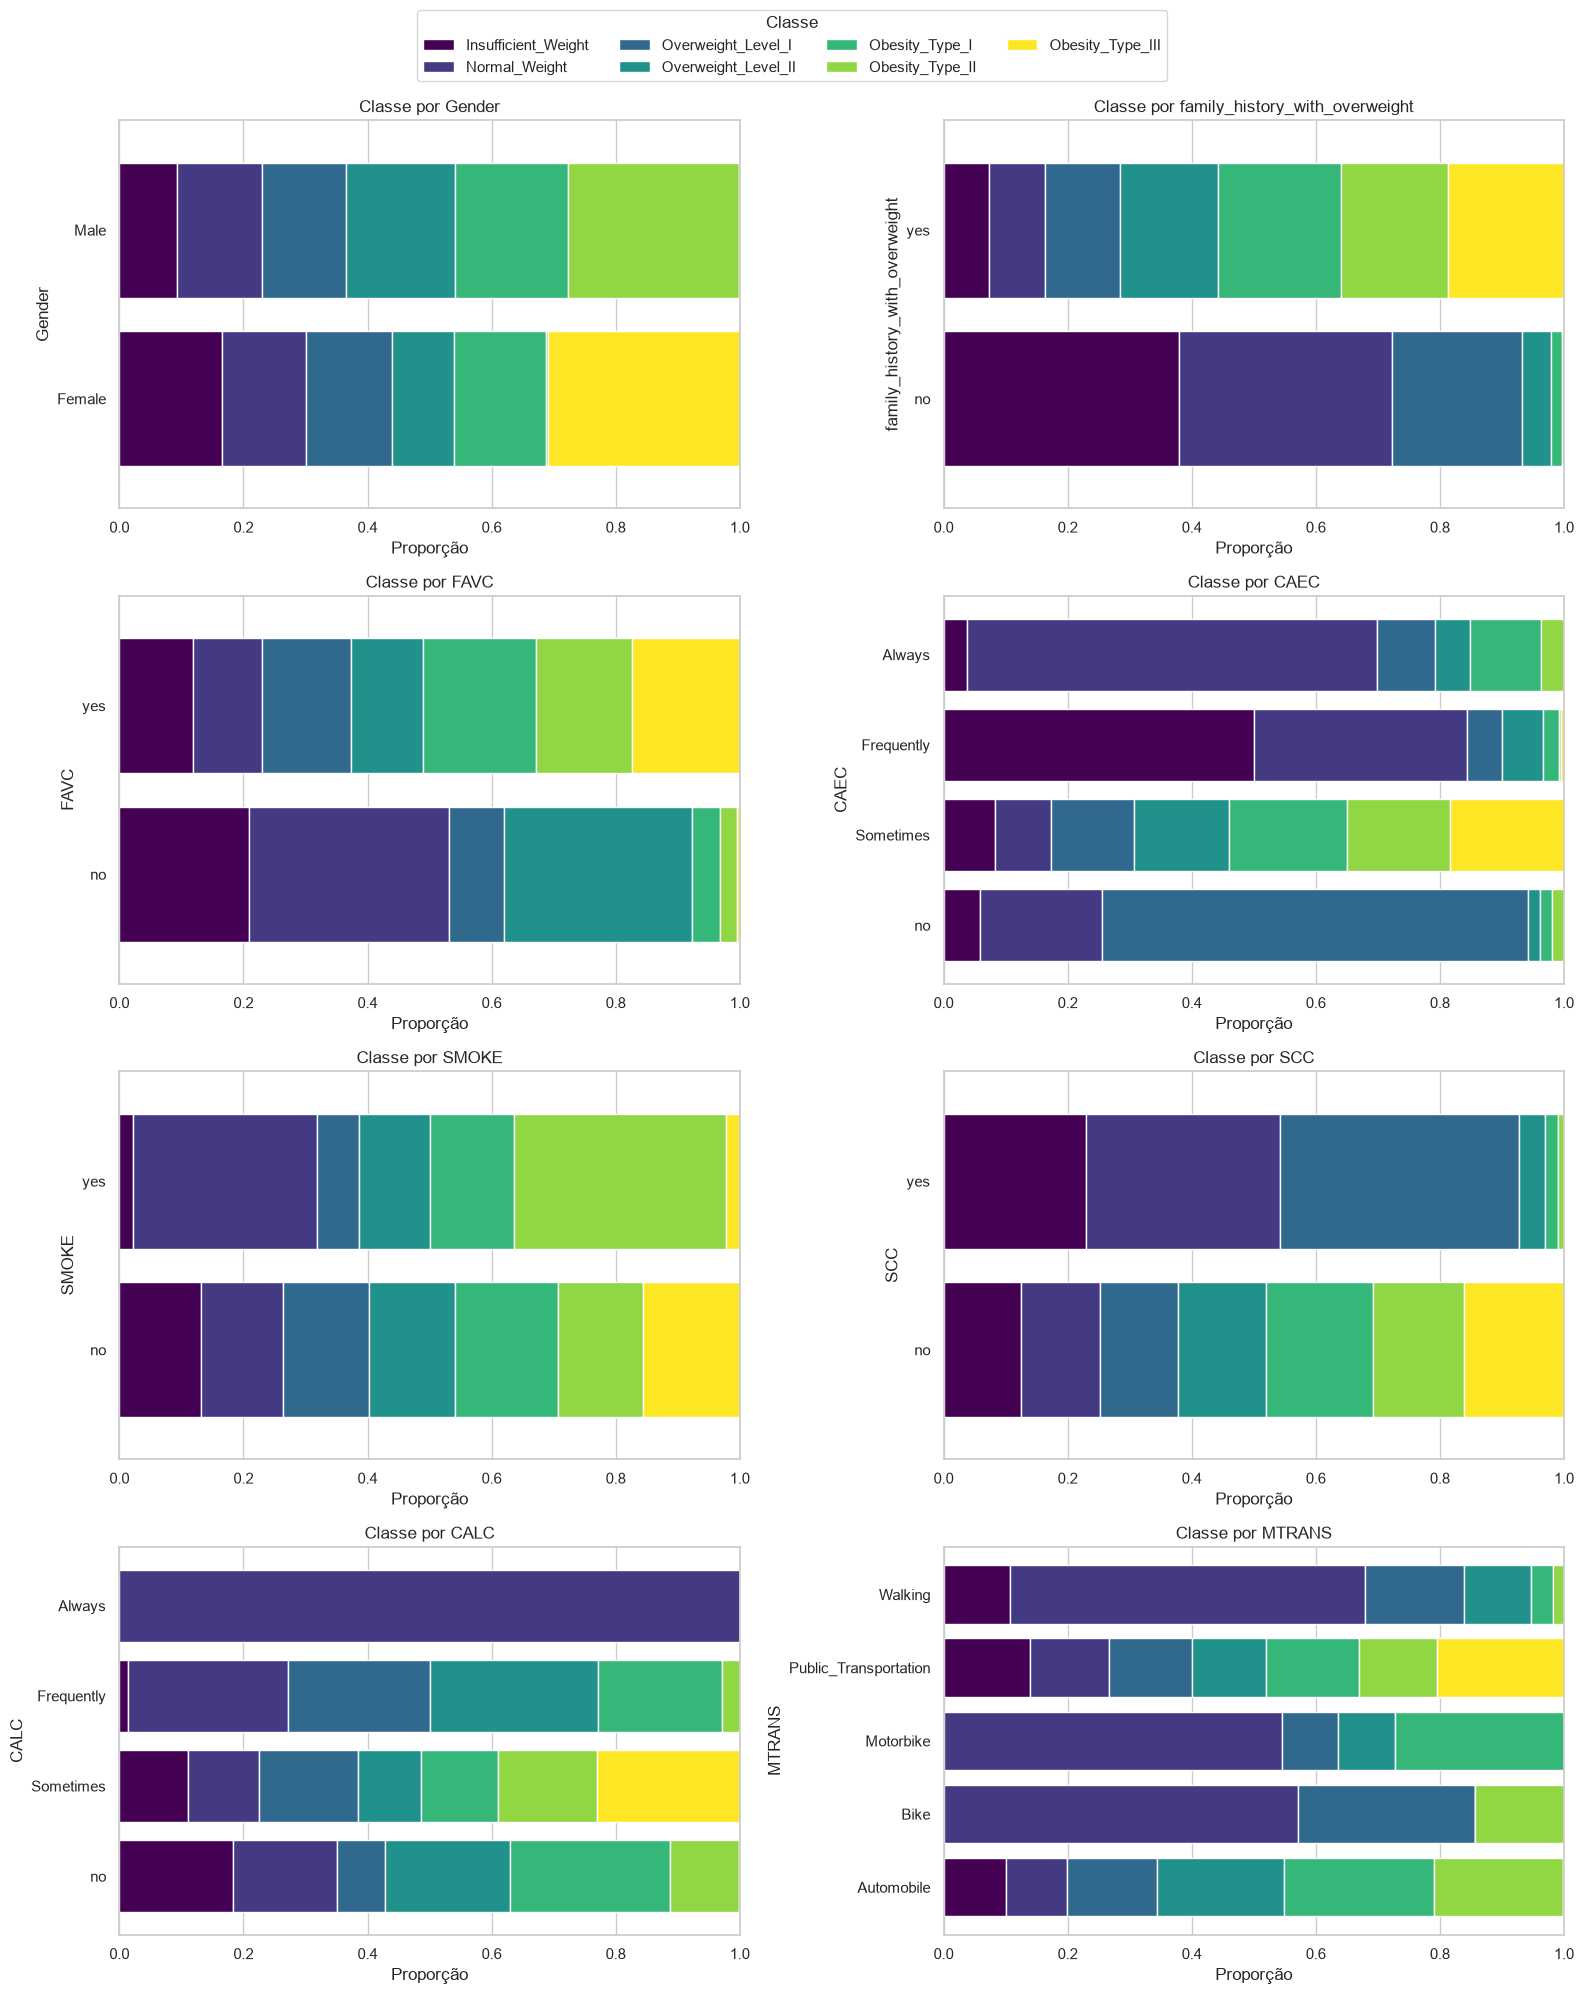

In [14]:
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
ORDEM_FREQ = ["no", "Sometimes", "Frequently", "Always"]  # ordem natural de CAEC e CALC
for ax, col in zip(axes.flat, cats_sem_alvo):
    prop = pd.crosstab(df[col], df[ALVO], normalize="index")
    if col in ("CAEC", "CALC"):
        prop = prop.reindex(ORDEM_FREQ)
    prop.plot(kind="barh", stacked=True, ax=ax, colormap="viridis", width=0.8, legend=False)
    ax.set_title(f"Classe por {col}")
    ax.set_xlabel("Proporção")
    ax.set_ylabel(col)
    ax.set_xlim(0, 1)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.legend(handles, labels, title="Classe", loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.0))
salvar(fig, "prop_categoricas_classe.png")
plt.show()

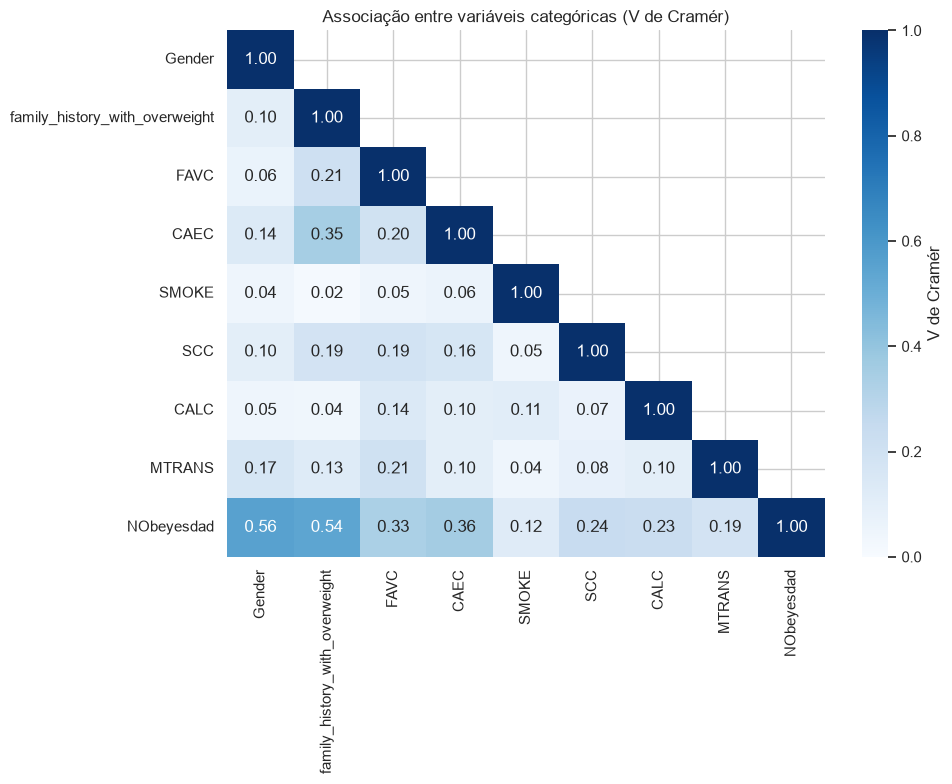

In [15]:
def cramers_v(a, b):
    tab = pd.crosstab(a, b).to_numpy(dtype=float)
    n = tab.sum()
    esperado = tab.sum(1, keepdims=True) * tab.sum(0, keepdims=True) / n
    qui2 = ((tab - esperado) ** 2 / esperado).sum()
    r, k = tab.shape
    return np.sqrt(qui2 / (n * (min(r, k) - 1))) if min(r, k) > 1 else np.nan

v = pd.DataFrame(index=categoricas, columns=categoricas, dtype=float)
for a in categoricas:
    for b in categoricas:
        v.loc[a, b] = cramers_v(df[a], df[b])

fig, ax = plt.subplots(figsize=(10, 8))
mascara = np.triu(np.ones_like(v, dtype=bool), k=1)
sns.heatmap(v, mask=mascara, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            cbar_kws={"label": "V de Cramér"}, ax=ax)
ax.set_title("Associação entre variáveis categóricas (V de Cramér)")
fig.tight_layout()
salvar(fig, "cramers_v.png")
plt.show()

> ✍️ **Análise do grupo:**

**Variável mais ligada à classe.** A variável mais ligada à classe é o peso, com eta² de 0,85. Isso faz sentido porque as classes representam níveis de obesidade, que são definidos principalmente pela relação entre peso e altura. Assim, o peso já separa fortemente as categorias.

**Altura × peso.** O gráfico mostra que as classes formam faixas de peso de acordo com a altura. Para pessoas com altura parecida, o aumento do peso acompanha a mudança de peso insuficiente para normal, sobrepeso e obesidade. Existe alguma sobreposição nas fronteiras, mas as categorias aparecem relativamente separadas. Também aparecem faixas e concentrações muito regulares, possivelmente por causa dos dados sintéticos.

**Relação que chamou atenção.** A associação de 0,56 (V de Cramér) entre gênero e classe chamou atenção, porque gênero não define diretamente o nível de obesidade. Essa associação pode estar ligada às diferenças de altura e peso entre os grupos, à composição da amostra ou ao processo de geração sintética. Ela indica associação, não que o gênero cause obesidade.

## 4. Outliers

Dois critérios:
- **IQR**: valor abaixo de Q1 − 1,5·IQR ou acima de Q3 + 1,5·IQR
- **Z-score**: |z| > 3

In [16]:
q1, q3 = df[numericas].quantile(0.25), df[numericas].quantile(0.75)
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
mask_iqr = (df[numericas] < lim_inf) | (df[numericas] > lim_sup)
z = (df[numericas] - df[numericas].mean()) / df[numericas].std()
mask_z = z.abs() > 3

outliers = pd.DataFrame({
    "limite_inf (IQR)": lim_inf,
    "limite_sup (IQR)": lim_sup,
    "outliers IQR": mask_iqr.sum(),
    "% IQR": mask_iqr.mean() * 100,
    "outliers |z|>3": mask_z.sum(),
})
print(f"Linhas com ao menos um outlier (IQR): {mask_iqr.any(axis=1).sum()}")
outliers

Linhas com ao menos um outlier (IQR): 702


,limite_inf (IQR),limite_sup (IQR),outliers IQR,% IQR,outliers |z|>3
Age,10.868,35.079,168,7.958,24
Height,1.422,1.976,1,0.047,0
Weight,2.537,170.367,1,0.047,1
FCVC,0.500,4.500,0,0.000,0
NCP,2.147,3.512,579,27.428,0
CH2O,0.246,3.816,0,0.000,0
FAF,-2.189,3.980,0,0.000,0
TUE,-1.500,2.500,0,0.000,0


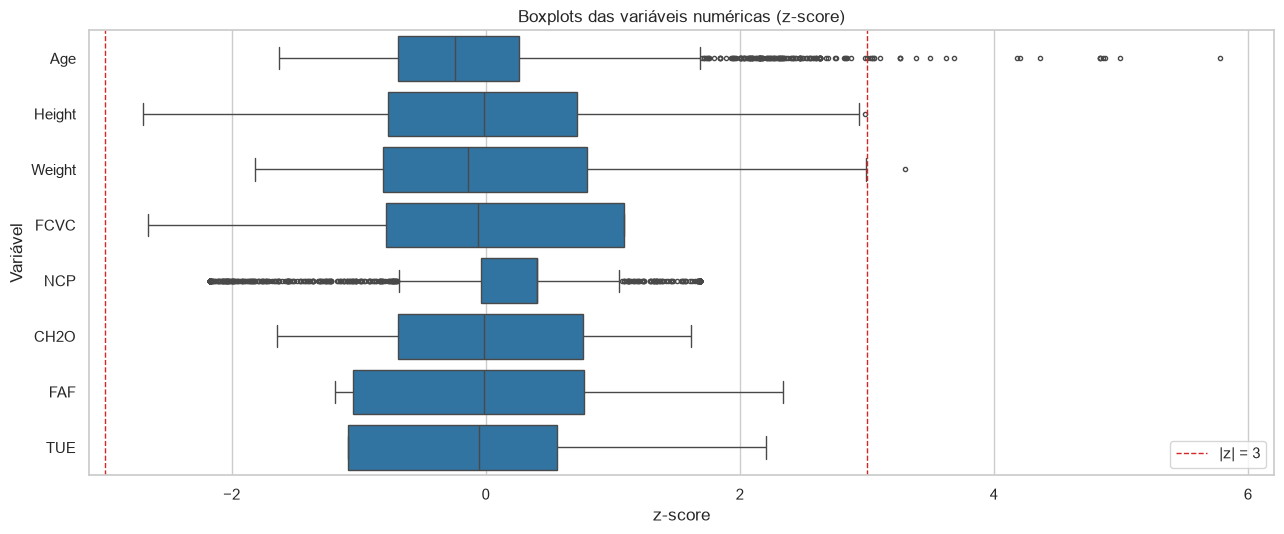

In [17]:
fig, ax = plt.subplots(figsize=(13, 5.5))
sns.boxplot(data=z, orient="h", ax=ax, color="tab:blue", fliersize=3)
ax.axvline(-3, color="tab:red", linestyle="--", linewidth=1)
ax.axvline(3, color="tab:red", linestyle="--", linewidth=1, label="|z| = 3")
ax.set_title("Boxplots das variáveis numéricas (z-score)")
ax.set_xlabel("z-score")
ax.set_ylabel("Variável")
ax.legend()
fig.tight_layout()
salvar(fig, "box_outliers.png")
plt.show()

In [18]:
for col in outliers.index[outliers["outliers IQR"] > 0]:
    linhas = df.loc[mask_iqr[col]]
    print(f"\n{col}: {len(linhas)} outliers | valores de {linhas[col].min():.2f} a {linhas[col].max():.2f}")
    print(linhas[ALVO].value_counts().loc[lambda s: s > 0].to_string())


Age: 168 outliers | valores de 35.13 a 61.00
NObeyesdad
Obesity_Type_I         70
Overweight_Level_II    39
Obesity_Type_II        29
Overweight_Level_I     22
Normal_Weight           7
Insufficient_Weight     1

Height: 1 outliers | valores de 1.98 a 1.98
NObeyesdad
Obesity_Type_I    1

Weight: 1 outliers | valores de 173.00 a 173.00
NObeyesdad
Obesity_Type_III    1

NCP: 579 outliers | valores de 1.00 a 4.00
NObeyesdad
Insufficient_Weight    124
Overweight_Level_I     122
Obesity_Type_I         110
Overweight_Level_II     89
Normal_Weight           81
Obesity_Type_II         53


In [19]:
base = km.carregar_dados()
linhas = []
for nome, dados in [("Com duplicatas", base), ("Sem duplicatas", base.drop_duplicates().reset_index(drop=True))]:
    X_teste, _ = km.preparar_X(dados)
    linhas.append({
        "base": nome,
        "linhas": len(dados),
        "acurácia (k = 5)": km.avaliar_passada(dados, X_teste, 5)["acuracia"],
        "acurácia (k = 7)": km.avaliar_passada(dados, X_teste, 7)["acuracia"],
    })
pd.DataFrame(linhas).set_index("base")

,linhas,acurácia (k = 5),acurácia (k = 7)
base,,,
Com duplicatas,2111,0.334,0.388
Sem duplicatas,2087,0.328,0.382


> ✍️ **Análise do grupo:**

**Idade, altura e peso.** Esses valores podem ser reais. Uma pessoa de 40 anos não é um erro, mesmo que a maioria da amostra seja mais jovem. Também é possível existir uma pessoa com 1,98 m ou 173 kg, principalmente em um dataset sobre obesidade. Mantivemos esses registros, pois não há evidência de erro de digitação.

**Refeições (NCP).** Uma pessoa pode fazer uma ou quatro refeições principais por dia. O IQR marcou esses valores como outliers porque 57% das pessoas possuem exatamente três refeições, deixando o intervalo central muito estreito. Nesse caso, ser um outlier estatístico não significa ser um valor errado.

**Duplicatas.** Mantivemos as duplicatas, porque o dataset não possui um identificador individual e pessoas diferentes podem apresentar respostas exatamente iguais. Além disso, são apenas 24 linhas, aproximadamente 1,1% da base, e a remoção altera a acurácia em somente cerca de 0,6 a 0,7 ponto percentual, como mostra o teste acima, feito com e sem as duplicatas.